# Задача 6

Решить задачу Коши

$$
    \frac{dx}{dt}=-x, \qquad x(0)=1, \qquad 0<t<3
$$

методом Эйлера первого порядка точности и методами Рунге–Кутты
второго и четвёртого порядка точности.

---

## Точное решение и равномерная сетка.

Разделим переменные:

$$
    \frac{dx}{x}=-dt \quad\Rightarrow\quad x(t)=Ce^{-t}.
$$

Из $x(0)=1$ находим $C=1$, поэтому

$$
    \boxed{x(t)=e^{-t}}, \qquad x(3)=e^{-3}\approx0.049787068367864.
$$

Точное решение используем для проверки численных методов.
Возьмём сетку $t_i=ih$, $h=3/N$, $i=0,\ldots,N$.
Значения численного решения обозначим $y_i\approx x(t_i)$.
Включим точку $t=3$, чтобы сравнить значения в конце отрезка.

In [56]:
import numpy as np
import matplotlib.pyplot as plt

t0 = 0.0
T = 10.0
x0 = 1.0
N = 30


def f(t, x):
    return x


def exact(t):
    return np.exp(np.asarray(t))

## Метод Эйлера.

Используем явную формулу

$$
    y_{i+1}=y_i+h f(t_i,y_i), \qquad y_0=1.
$$

При $f(t,x)=-x$ получаем

$$
    y_{i+1}=(1-h)y_i, \qquad y_i=(1-h)^i.
$$

Ошибка одного шага при точном начальном значении равна $O(h^2)$,
глобальная ошибка на фиксированном отрезке — $O(h)$.

In [57]:
def step_euler(func, t, y, h):
    return y + h * func(t, y)

## Метод Рунге–Кутты второго порядка.

Возьмём явный метод средней точки, как в лекции:

$$
\begin{aligned}
    k_1&=f(t_i,y_i),\\
    k_2&=f\!\left(t_i+\frac h2,y_i+\frac h2 k_1\right),\\
    y_{i+1}&=y_i+h k_2.
\end{aligned}
$$

Для нашего уравнения $k_1=-y_i$, $k_2=-y_i(1-h/2)$, поэтому

$$
    y_{i+1}=\left(1-h+\frac{h^2}{2}\right)y_i.
$$

Ошибка одного шага равна $O(h^3)$, глобальная ошибка — $O(h^2)$.

In [58]:
def step_rk2(func, t, y, h):
    k1 = func(t, y)
    k2 = func(t + h/2, y + h*k1/2)
    return y + h*k2

## Метод Рунге–Кутты четвёртого порядка.

Используем классическую четырёхстадийную схему:

$$
\begin{aligned}
    k_1&=f(t_i,y_i),\\
    k_2&=f\!\left(t_i+\frac h2,y_i+\frac h2k_1\right),\\
    k_3&=f\!\left(t_i+\frac h2,y_i+\frac h2k_2\right),\\
    k_4&=f(t_i+h,y_i+hk_3),\\
    y_{i+1}&=y_i+\frac h6(k_1+2k_2+2k_3+k_4).
\end{aligned}
$$

Подставляя $f=-x$, получаем

$$
    y_{i+1}=\left(1-h+\frac{h^2}{2}-\frac{h^3}{6}
    +\frac{h^4}{24}\right)y_i.
$$

Ошибка одного шага равна $O(h^5)$, глобальная ошибка — $O(h^4)$.

In [59]:
def step_rk4(func, t, y, h):
    k1 = func(t, y)
    k2 = func(t + h/2, y + h*k1/2)
    k3 = func(t + h/2, y + h*k2/2)
    k4 = func(t + h, y + h*k3)
    return y + h*(k1 + 2*k2 + 2*k3 + k4)/6

## Решение на сетке.

Все три метода отличаются только формулой одного шага.
Поэтому цикл по сетке вынесем в общую функцию.

In [60]:
def solve_ode(func, t0, T, y0, N, step):
    if not isinstance(N, (int, np.integer)) or N < 1:
        raise ValueError("N должно быть положительным целым числом")
    t = np.linspace(t0, T, N + 1)
    h = (T - t0) / N
    y = np.empty(N + 1)
    y[0] = y0
    for i in range(N):
        y[i+1] = step(func, t[i], y[i], h)
    return t, y


methods = [("Эйлер", step_euler, 1),
           ("РК2", step_rk2, 2),
           ("РК4", step_rk4, 4)]
solutions = {}
for name, step, order in methods:
    t_grid, y = solve_ode(f, t0, T, x0, N, step)
    solutions[name] = y

x_exact = exact(t_grid)
print("N =", N, "h =", (T-t0)/N)
for i in np.linspace(0, N, 7, dtype=int):
    print("\nt =", t_grid[i], "Точное решение:", x_exact[i])
    for name, _, _ in methods:
        print(name, solutions[name][i])

for name, _, _ in methods:
    error = solutions[name] - x_exact
    print("\nМетод:", name)
    print("y(3) =", solutions[name][-1])
    print("Ошибка при t=3:", abs(error[-1]))
    print("Максимальная ошибка:", np.max(np.abs(error)))

N = 30 h = 0.3333333333333333

t = 0.0 Точное решение: 1.0
Эйлер 1.0
РК2 1.0
РК4 1.0

t = 1.6666666666666665 Точное решение: 5.294490050470029
Эйлер 4.213991769547325
РК2 5.168178652475063
РК4 5.293801660764631

t = 3.333333333333333 Точное решение: 28.031624894526125
Эйлер 17.757726633812588
РК2 26.710070583898954
РК4 28.02433602351436

t = 5.0 Точное решение: 148.4131591025766
Эйлер 74.83091388075755
РК2 138.0424165978087
РК4 148.3552765831064

t = 6.666666666666666 Точное решение: 785.7719942274168
Эйлер 315.33685520121696
РК2 713.4278705968642
РК4 785.3634095588448

t = 8.333333333333332 Точное решение: 4160.26200537505
Эйлер 1328.8269124528647
РК2 3687.1226908994554
РК4 4157.558121826385

t = 10.0 Точное решение: 22026.465794806718
Эйлер 5599.665672229354
РК2 19055.70878016297
РК4 22009.288090049995

Метод: Эйлер
y(3) = 5599.665672229354
Ошибка при t=3: 16426.800122577362
Максимальная ошибка: 16426.800122577362

Метод: РК2
y(3) = 19055.70878016297
Ошибка при t=3: 2970.757014643746

## Графики решения и ошибок.

Слева сравним численные решения с $e^{-t}$, справа покажем разность
$y_i-e^{-t_i}$. Для каждого метода используем свою шкалу ошибок,
чтобы было видно результат РК4.

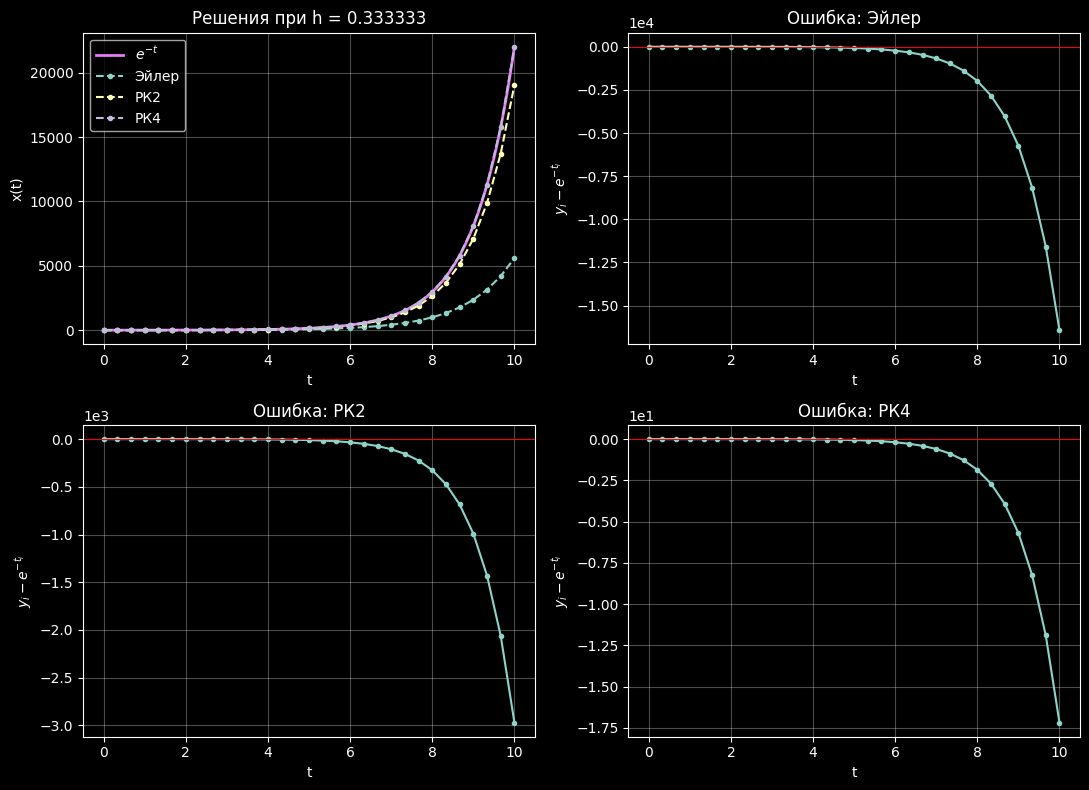

In [61]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
ax = axes[0, 0]
t_fine = np.linspace(t0, T, 601)
ax.plot(t_fine, exact(t_fine), color="#e879f9", linewidth=2, label=r"$e^{-t}$")
for name, _, _ in methods:
    ax.plot(t_grid, solutions[name], "o--", markersize=3, label=name)
ax.set(xlabel="t", ylabel="x(t)", title=f"Решения при h = {(T-t0)/N:g}")
ax.legend()

for ax, (name, _, _) in zip([axes[0, 1], axes[1, 0], axes[1, 1]], methods):
    ax.plot(t_grid, solutions[name] - x_exact, "o-", markersize=3)
    ax.axhline(0, color="red", linewidth=0.7)
    ax.set(xlabel="t", ylabel=r"$y_i-e^{-t_i}$", title="Ошибка: " + name)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
for ax in axes.flat:
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Проверка порядка точности.

Для всех методов используем одни и те же сгущающиеся сетки.
Определим глобальную ошибку как максимум по всем узлам, включая края:

$$
    E_N=\max_{0\le i\le N}|y_i-e^{-t_i}|.
$$

Если $E_N\approx Ch^p$, то при удвоении числа шагов

$$
    p_{\mathrm{набл}}=\log_2\frac{E_N}{E_{2N}}\longrightarrow p.
$$

Ожидаем $p=1,2,4$, то есть уменьшение ошибки примерно в $2,4,16$ раз.

In [62]:
N_values = np.array([15, 30, 60, 120, 240, 480])
convergence = {}
for name, step, theoretical_order in methods:
    errors = []
    orders = []
    print("\nМетод:", name)
    for n in N_values:
        t, y = solve_ode(f, t0, T, x0, n, step)
        error = np.max(np.abs(y - exact(t)))
        order = np.log2(errors[-1]/error) if errors and error > 0 else np.nan
        order_text = round(order, 3) if np.isfinite(order) else "—"
        print("N =", n, "h =", (T-t0)/n, "Ошибка:", error, "Порядок:", order_text)
        errors.append(error)
        orders.append(order)
    convergence[name] = dict(errors=np.array(errors), orders=np.array(orders))


Метод: Эйлер
N = 15 h = 0.6666666666666666 Ошибка: 19899.64330407624 Порядок: —
N = 30 h = 0.3333333333333333 Ошибка: 16426.800122577362 Порядок: 0.277
N = 60 h = 0.16666666666666666 Ошибка: 11631.87546050958 Порядок: 0.498
N = 120 h = 0.08333333333333333 Ошибка: 7185.821663939363 Порядок: 0.695
N = 240 h = 0.041666666666666664 Ошибка: 4041.7296556349975 Порядок: 0.83
N = 480 h = 0.020833333333333332 Ошибка: 2150.6724128837122 Порядок: 0.91

Метод: РК2
N = 15 h = 0.6666666666666666 Ошибка: 8123.860945395594 Порядок: —
N = 30 h = 0.3333333333333333 Ошибка: 2970.7570146437465 Порядок: 1.451
N = 60 h = 0.16666666666666666 Ошибка: 882.5336210228124 Порядок: 1.751
N = 120 h = 0.08333333333333333 Ошибка: 238.23462287183793 Порядок: 1.889
N = 240 h = 0.041666666666666664 Ошибка: 61.68892764305929 Порядок: 1.949
N = 480 h = 0.020833333333333332 Ошибка: 15.681025692880212 Порядок: 1.976

Метод: РК4
N = 15 h = 0.6666666666666666 Ошибка: 208.06038831543265 Порядок: —
N = 30 h = 0.333333333333333

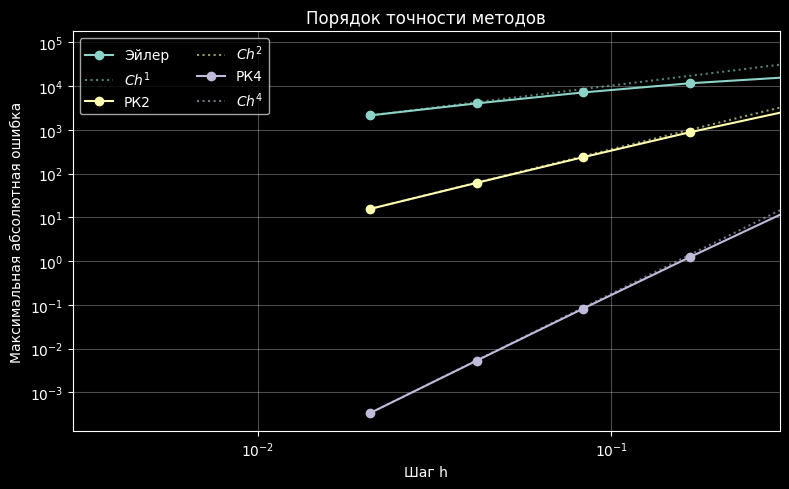

In [63]:
h_values = (T-t0) / N_values
fig, ax = plt.subplots(figsize=(8, 5))
for name, _, order in methods:
    errors = convergence[name]["errors"]
    line, = ax.loglog(h_values, errors, "o-", label=name)
    reference = errors[-1] * (h_values/h_values[-1])**order
    ax.loglog(h_values, reference, ":", color=line.get_color(), alpha=0.6,
              label=rf"$C h^{order}$")
ax.set(xlabel="Шаг h", ylabel="Максимальная абсолютная ошибка",
       title="Порядок точности методов")
ax.set_xticks([1e-3, 1e-2, 1e-1, 1],
              [r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$", r"$10^0$"])
ax.set_xlim(3e-3, 0.3)
ax.minorticks_off()
ax.grid(True, alpha=0.3)
ax.legend(ncols=2)
fig.tight_layout()
plt.show()

## Устойчивость и независимая проверка.

Для $x'=-x$ каждый шаг умножает решение на свой коэффициент:

$$
\begin{aligned}
    R_1(h)&=1-h,\\
    R_2(h)&=1-h+\frac{h^2}{2},\\
    R_4(h)&=1-h+\frac{h^2}{2}-\frac{h^3}{6}+\frac{h^4}{24}.
\end{aligned}
$$

Возмущения убывают при $|R(h)|<1$. Для Эйлера и РК2 это $0<h<2$;
для классического РК4 вдоль отрицательной вещественной оси —
приблизительно $0<h<2.7853$.
Все использованные для сравнения шаги лежат внутри этих интервалов.

При $0<h<1$ для Эйлера имеем $1-h<e^{-h}$, поэтому численное
решение ниже точного. Для РК2 и РК4 соответствующие многочлены
выше $e^{-h}$ при $h>0$, что объясняет знак ошибок на графиках.

Проверим реализацию по формулам $y_i=R(h)^i$, полученным непосредственно
из схем. Это отдельная проверка кода; порядок выше проверен по точному
решению $e^{-t}$.

In [64]:
h = (T-t0)/N
factors = {"Эйлер": 1-h,
           "РК2": 1-h+h**2/2,
           "РК4": 1-h+h**2/2-h**3/6+h**4/24}
for name, _, _ in methods:
    powers = x0 * factors[name]**np.arange(N+1)
    difference = np.max(np.abs(solutions[name] - powers))
    print(name, "R(h) =", factors[name], "Максимальное расхождение:", difference)
    assert abs(factors[name]) < 1
    assert difference < 1e-13
    assert solutions[name][0] == x0
print("Начальное условие и формулы сеточного решения проверены.")

Эйлер R(h) = 0.6666666666666667 Максимальное расхождение: 5599.665667014258


AssertionError: 

## Ответ.

Точное решение задачи Коши:

$$
    \boxed{x(t)=e^{-t}}.
$$

Численные решения на равномерной сетке $t_i=ih$ имеют вид

$$
\boxed{
\begin{aligned}
    y_i^{\mathrm{Э}}&=(1-h)^i,\\
    y_i^{\mathrm{РК2}}&=\left(1-h+\frac{h^2}{2}\right)^i,\\
    y_i^{\mathrm{РК4}}&=\left(1-h+\frac{h^2}{2}-\frac{h^3}{6}
    +\frac{h^4}{24}\right)^i.
\end{aligned}}
$$

Таблицы и графики показывают сходимость к $e^{-t}$.
Наблюдаемые глобальные порядки стремятся к $1$, $2$ и $4$ соответственно.
При одинаковом шаге на рассмотренных сетках наиболее точен РК4.